# Part 1 · Finding the depth of a buried sphere by brute-force search

**All data in this notebook are SYNTHETIC**, computed with the sphere formula below. No field data.

**Question:** given gravity readings along a line over a buried sphere, which depth fits them best? And what happens to that depth if the assumed density contrast is wrong?

## 0 · Forward model: vertical gravity of a buried sphere
g_z(x) = G · ΔM · z / ((x − x0)² + z²)^(3/2), with ΔM = (4/3)πR³Δρ, converted to mGal (1 m/s² = 10⁵ mGal).

In [16]:
import numpy as np
import matplotlib.pyplot as plt

G = 6.674e-11          # m^3 kg^-1 s^-2
SI_TO_MGAL = 1e5       # 1 m/s^2 = 1e5 mGal (plain number, no G)

def gz_sphere(x, x0, z, R, drho):
    """Vertical gravity (mGal) of a buried sphere at stations x (m).
    x0 = horizontal centre (m), z = depth to centre (m), R = radius (m), drho = density contrast (kg/m^3)."""
    assert R < z, "sphere must be fully buried (R < z)"
    dM = (4/3) * np.pi * R**3 * drho
    return G * dM * z / ((x - x0)**2 + z**2)**1.5 * SI_TO_MGAL

print("setup OK")

setup OK


## 1 · Residual, misfit and RMS
- residual r = d_obs − d_pred (one value per station, mGal)
- misfit φ = ‖r‖² = sum of r² (one number, mGal²)
- RMS = √(φ / N) (mGal), N = number of stations

Checked on a 3-station example worked by hand.

In [18]:
def misfit(d_obs, d_pred):
  r = d_obs - d_pred #r = residual
  return np.sum(r**2) #misfit


def rms(d_obs, d_pred):
  m = misfit(d_obs, d_pred)
  return np.sqrt((m)/len(d_obs))


d_obs_hand  = np.array([0.30, 0.50, 0.30])
d_pred_hand = np.array([0.20, 0.50, 0.40])
print("phi =", misfit(d_obs_hand, d_pred_hand), " RMS =", rms(d_obs_hand, d_pred_hand))
assert abs(misfit(d_obs_hand, d_pred_hand) - 0.02) < 1e-12, "misfit: residual first, then square, then sum"
assert abs(rms(d_obs_hand, d_pred_hand) - 0.0816) < 1e-4, "rms: divide by N before the square root"
print("M4 passed")

phi = 0.020000000000000004  RMS = 0.08164965809277261
M4 passed


## 2 · SYNTHETIC "observed" data
True body: x0 = 0 m, **z = 120 m**, R = 40 m, Δρ = 400 kg/m³. 101 stations from −500 to 500 m. No noise.

In [19]:
x = np.linspace(-500, 500, 101)      # 101 stations, -500 to 500 m
d_obs = gz_sphere(x, 0, 120, 40, 400)    # gz_sphere of the true body

print("N =", len(x), " peak =", round(d_obs.max(), 4), "mGal")
assert len(x) == 101 and abs(d_obs.max() - 0.0497) < 1e-4, "check x and the true-body numbers"
print("B1 passed")

N = 101  peak = 0.0497 mGal
B1 passed


## 3 · Scan trial depths and plot φ(z)
Trial depths 50–300 m in 1-m steps (the scan starts at 50 m because the sphere must stay buried: R = 40 m < z). x0, R and Δρ are kept at their true values.

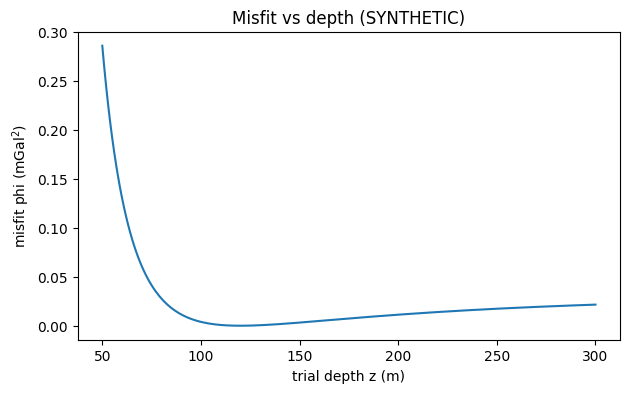

In [20]:
z_trial = np.linspace(50, 300, 251)               # 50 to 300 m in steps of 1 m
phi = np.zeros(len(z_trial))  # the shelf
for i in range(len(z_trial)):
  d_pred1 = gz_sphere(x, 0, z_trial[i], 40, 400)                       # d_pred for this depth, then phi[i]
  phi[i] = misfit(d_obs, d_pred1)


plt.figure(figsize=(7, 4))
plt.plot(z_trial, phi)
plt.xlabel("trial depth z (m)"); plt.ylabel("misfit phi (mGal$^2$)"); plt.title("Misfit vs depth (SYNTHETIC)")
plt.show()

## 4 · Best depth = the depth with the smallest misfit

In [23]:
min_index = np.argmin(phi)
z_best = z_trial[min_index]
print("best depth =", z_best, "m   phi_min =", phi.min())
assert z_best == 120, "use the index of the smallest phi to pick from z_trial"
print("B3 passed")

best depth = 120.0 m   phi_min = 0.0
B3 passed


## 5 · What if the assumed density contrast is wrong?
Same data, same scan, but assuming **Δρ = 200 kg/m³** (half the true value).

wrong-mass best depth = 81.0 m   phi_min = 0.0018234288682448846


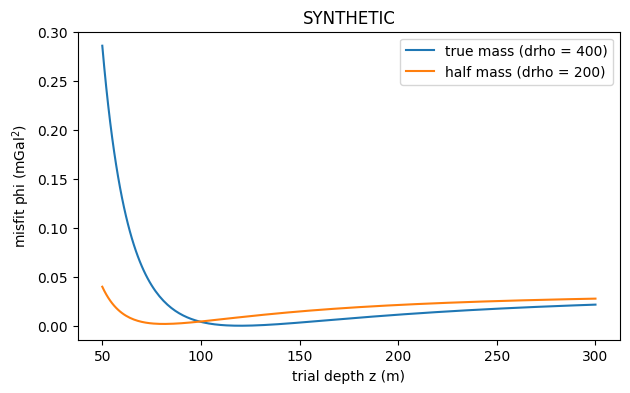

In [25]:
# B4: scan again, wrongly assuming drho = 200 (true is 400). d_obs stays the same.
phi_wrong = np.zeros(len(z_trial))            # empty shelf for the wrong-mass misfits
for i in range(len(z_trial)):
    d_pred_wrong = gz_sphere(x, 0, z_trial[i], 40, 200)   # one depth, half mass
    phi_wrong[i] = misfit(d_obs, d_pred_wrong)            # fill THIS shelf

z_best_wrong = z_trial[np.argmin(phi_wrong)]   # index -> depth (np.argmin(phi_wrong) - Gets the index of least misfit of the wrong prediction)
print("wrong-mass best depth =", z_best_wrong, "m   phi_min =", phi_wrong.min())

plt.figure(figsize=(7, 4))
plt.plot(z_trial, phi, label="true mass (drho = 400)")        # from B2
plt.plot(z_trial, phi_wrong, label="half mass (drho = 200)")
plt.xlabel("trial depth z (m)"); plt.ylabel("misfit phi (mGal$^2$)")
plt.legend(); plt.title("SYNTHETIC"); plt.show()

## Result
- True Δρ: best depth **120 m**, φ_min = 0 (noise-free data, so the true model fits exactly).
- Half Δρ: best depth **81 m** (shallower), φ_min ≈ 0.0018 mGal² > 0.
- With less assumed mass, a shallower body is needed to match the peak height, but then the curve is too narrow, so no depth fits all stations. The depth estimate depends on the assumed density: in a real survey it needs outside information (e.g. rock densities from samples or logs).